# Lab 5: Statistics for Displaying Sentinel-2 Images

**Name: Gaurav Parajuli**

**Date: 2026-10-20**

In this lab you use image statistics to make display decisions. You work with the two scenes you clipped in Lab 4: June 29, 2019 (clear) and July 14, 2019 (partly cloudy).

- **Part A. Stretch by the numbers:** compute one-band statistics, build four stretches from them, and choose your own stretch for a true-color image.
- **Part B. Choose bands with statistics:** use correlations, the Optimum Index Factor (OIF), the Sheffield Index (SI) and class statistics to pick three bands for a color composite.
- **Part C. Two dates, one picture:** compare a clear and a cloudy date with a cloud mask and fixed stretch limits.

Cells marked **Your turn** ask you to change something and run the cell again. The questions are at the end.

## Settings

In [2]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from scipy import stats

DATA_DIR = Path("sentinel2") / "clipped"          # the clipped stacks from Lab 4
OUT_DIR = Path("lab5_outputs")                     # figures you save in this lab
OUT_DIR.mkdir(exist_ok=True)
DATES = ["20190629", "20190714"]
LABEL = {"20190629": "June 29 (clear)", "20190714": "July 14 (cloudy)"}
CLEAR = [4, 5, 6]            # SCL classes: vegetation, not vegetated, water
CLOUDY = [3, 8, 9, 10]       # SCL classes: cloud shadow, medium and high cloud, thin cirrus
SCL_NAMES = {3: "Cloud shadow", 4: "Vegetation", 5: "Not vegetated", 6: "Water",
             8: "Cloud (medium)", 9: "Cloud (high)", 10: "Thin cirrus"}

for d in DATES:
    for kind in ["20m", "SCL"]:
        f = DATA_DIR / f"S2_T14SQH_{d}_{kind}.tif"
        print(f"{f}: {'found' if f.exists() else 'NOT FOUND - check Lab 4 and DATA_DIR'}")

sentinel2\clipped\S2_T14SQH_20190629_20m.tif: found
sentinel2\clipped\S2_T14SQH_20190629_SCL.tif: found
sentinel2\clipped\S2_T14SQH_20190714_20m.tif: found
sentinel2\clipped\S2_T14SQH_20190714_SCL.tif: found


Read both 20 m stacks and their SCL, and convert stored values (DN) to reflectance: reflectance = (DN − 1000) / 10000, with DN 0 = no data.

In [3]:
def read_scene(date):
    with rasterio.open(DATA_DIR / f"S2_T14SQH_{date}_20m.tif") as src:
        dn = src.read()
        names = [b.split()[0] for b in src.descriptions]
        tags = src.tags()
    refl = (dn.astype("float32") + float(tags["BOA_ADD_OFFSET"])) / float(tags["BOA_QUANTIFICATION_VALUE"])
    refl[:, dn[0] == 0] = np.nan
    with rasterio.open(DATA_DIR / f"S2_T14SQH_{date}_SCL.tif") as src:
        scl = src.read(1)
    return refl, scl, names

REFL, SCL = {}, {}
for d in DATES:
    REFL[d], SCL[d], BAND = read_scene(d)
B = {b: i for i, b in enumerate(BAND)}
CLEAR_MASK = {d: np.isin(SCL[d], CLEAR) & ~np.isnan(REFL[d][0]) for d in DATES}
print("Bands:", BAND)
for d in DATES:
    print(f"{LABEL[d]}: clear pixels {100 * CLEAR_MASK[d].sum() / (~np.isnan(REFL[d][0])).sum():.1f}%")

Bands: ['B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B8A', 'B11', 'B12']
June 29 (clear): clear pixels 98.7%
July 14 (cloudy): clear pixels 38.7%


### Helper functions

These are the same steps as in the lecture notebook. `limits()` finds stretch limits from the data, `linear()` applies a linear stretch, `equalize()` does histogram equalization, `log_curve()` is the logarithmic stretch curve, and `composite()` builds a color image from three bands, each stretched on its own. Run the cell; you do not need to change it.

In [4]:
def valid_values(x, mask=None):
    return x[~np.isnan(x)] if mask is None else x[mask & ~np.isnan(x)]

def limits(x, method="pct", mask=None, p=(2, 98), n=2.0):
    """Low and high stretch limits: 'minmax', 'pct' (percent clip p) or 'std' (mean +/- n std)."""
    v = valid_values(x, mask)
    if method == "minmax":
        return float(v.min()), float(v.max())
    if method == "pct":
        lo, hi = np.percentile(v, p)
        return float(lo), float(hi)
    if method == "std":
        return float(v.mean() - n * v.std()), float(v.mean() + n * v.std())
    raise ValueError(method)

def linear(x, lo, hi):
    return np.clip((x - lo) / (hi - lo), 0, 1)

def equalize(x, mask=None, nbins=4096):
    """Histogram equalization: output = cumulative share of pixels <= x."""
    counts, edges = np.histogram(valid_values(x, mask), bins=nbins)
    cdf = np.cumsum(counts) / counts.sum()
    return np.interp(x, edges[1:], cdf)

def log_curve(u, c=99):
    """Logarithmic stretch of u in 0-1: log(1 + c*u) / log(1 + c)."""
    return np.clip(np.log1p(c * u) / np.log1p(c), 0, 1)    # clip guards against rounding just above 1

def composite(refl, bands, method="pct", mask=None, fixed=None, gamma=1.0, c=99, **kw):
    """(rows, cols, 3) image in 0-1 from three bands in red, green, blue order.
    method: 'minmax', 'pct', 'std', 'equalize' or 'log' (min-max, then log_curve with c);
    fixed=(lo, hi) uses the same limits for every band."""
    out = []
    for b, g in zip(bands, np.broadcast_to(np.asarray(gamma, dtype="float32"), (3,))):
        x = refl[B[b]]
        if method == "equalize":
            y = equalize(x, mask)
        elif method == "log":
            y = log_curve(linear(x, *limits(x, "minmax", mask)), c)
        else:
            lo, hi = fixed if fixed is not None else limits(x, method, mask, **kw)
            y = linear(x, lo, hi)
        out.append(y ** (1 / g))
    return np.nan_to_num(np.dstack(out), nan=1.0)

def show(ax, img, title):
    ax.imshow(img)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()

## Part A. Stretch by the numbers

### A1. One-band statistics

Compute the statistics from the image-statistics lecture for the three true-color bands, on **clear pixels of June 29** only (SCL 4, 5, 6).

In [5]:
def band_stats(refl, bands, mask):
    rows = {}
    for b in bands:
        v = valid_values(refl[B[b]], mask)
        p2, p98 = np.percentile(v, [2, 98])
        rows[b] = {"n": v.size, "min": v.min(), "p2": p2, "median": np.median(v), "mean": v.mean(),
                   "p98": p98, "max": v.max(), "std": v.std(ddof=1), "skew": stats.skew(v)}
    return pd.DataFrame(rows).T

d = "20190629"
TC = ["B04", "B03", "B02"]                       # true color: red, green, blue
tc_stats = band_stats(REFL[d], TC, CLEAR_MASK[d])
tc_stats.round(4)

,n,min,p2,median,mean,p98,max,std,skew
B04,5419594.0,0.0130,0.0256,0.0569,0.0743,0.1800,1.0919,0.0428,1.5186
B03,5419594.0,0.0222,0.0468,0.0768,0.0849,0.1517,1.0830,0.0265,2.3931
B02,5419594.0,0.0154,0.0231,0.0427,0.0537,0.1212,1.0697,0.0271,2.4145


### A2. Four stretches built from these statistics

Each stretch takes its limits from the table above:

- **min–max:** the `min` and `max` columns
- **percent clip (2–98%):** the `p2` and `p98` columns
- **standard deviation (n = 2):** `mean` − 2 `std` to `mean` + 2 `std`
- **histogram equalization:** the cumulative histogram of each band

The right-hand panel shows how each stretch maps the red band's reflectance to the screen, over the red band's histogram.

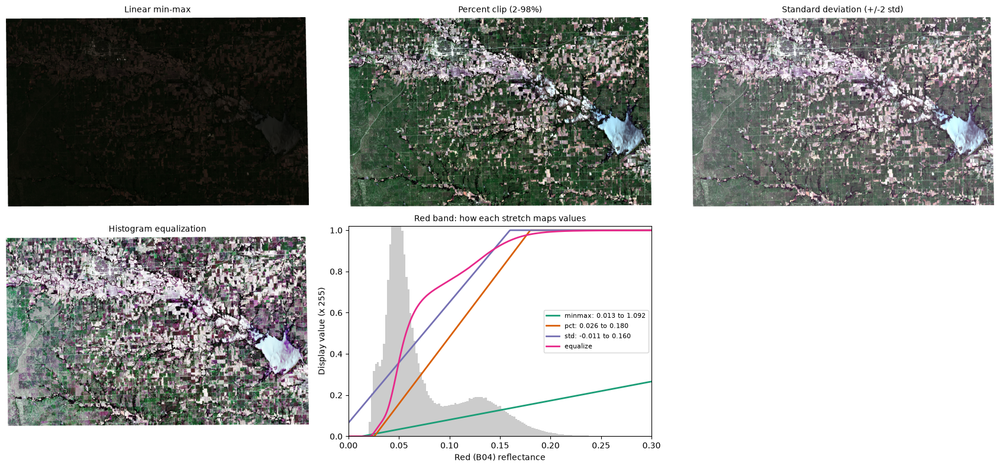

In [6]:
methods = [("minmax", "Linear min-max"), ("pct", "Percent clip (2-98%)"),
           ("std", "Standard deviation (+/-2 std)"), ("equalize", "Histogram equalization")]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (m, title) in zip(axes.flat, methods):
    show(ax, composite(REFL[d], TC, m, CLEAR_MASK[d]), title)

ax = axes.flat[4]
red = REFL[d][B["B04"]]
v = valid_values(red, CLEAR_MASK[d])
xs = np.linspace(0, 0.3, 600)
ax.hist(v, bins=np.linspace(0, 0.3, 150), color="0.8", weights=np.full(v.size, 25 / v.size))
for m, color in [("minmax", "#1b9e77"), ("pct", "#d95f02"), ("std", "#7570b3")]:
    lo, hi = limits(red, m, CLEAR_MASK[d])
    ax.plot(xs, linear(xs, lo, hi), color=color, lw=2, label=f"{m}: {lo:.3f} to {hi:.3f}")
ax.plot(xs, np.interp(xs, np.sort(v), np.linspace(0, 1, v.size)), color="#e7298a", lw=2, label="equalize")
ax.set_xlim(0, 0.3); ax.set_ylim(0, 1.02); ax.legend(fontsize=8)
ax.set_xlabel("Red (B04) reflectance"); ax.set_ylabel("Display value (x 255)")
ax.set_title("Red band: how each stretch maps values", fontsize=10)
axes.flat[5].set_axis_off()
plt.tight_layout()
plt.show()

### A3. Your turn: your best true-color image

Change the settings below until you have the true-color image you would put in a report, then run the cell. Try at least two settings. You can change:

- `METHOD`: `"pct"`, `"std"`, `"minmax"`, `"equalize"` or `"log"` (min–max, then the logarithmic curve)
- `P`: the percentiles of a percent clip, for example `(1, 99)` or `(0.5, 99.5)`
- `N`: the number of standard deviations for `"std"`, for example `2.5`
- `C`: the strength of the `"log"` curve, output = log(1 + C·u) / log(1 + C); for example `20` (mild) or `99`
- `GAMMA`: one value for all bands, or three values (red, green, blue)

The cell prints the limits it used for each band and saves the image to `lab5_outputs`.

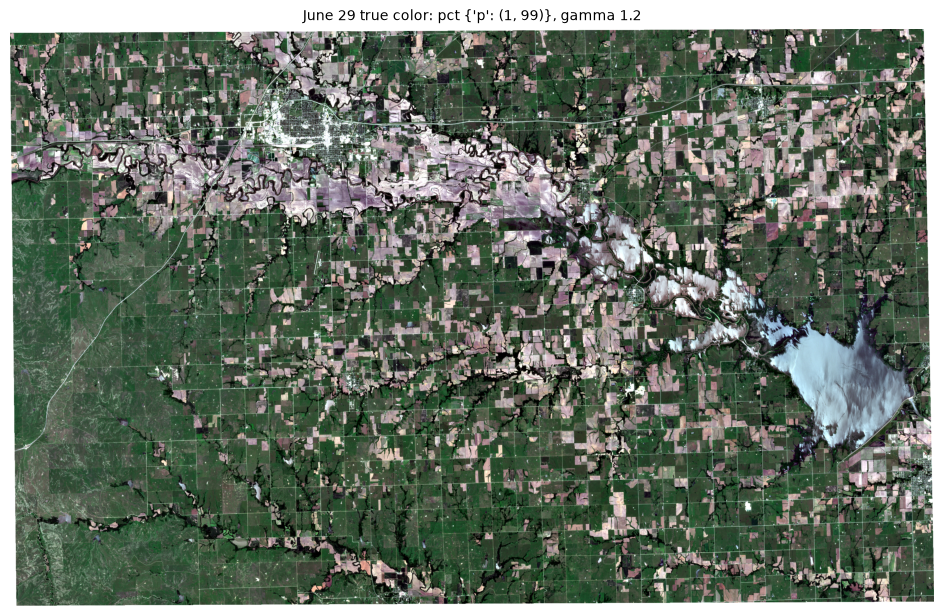

B04: 0.0239 to 0.1949  (DN 1239 to 2949)
B03: 0.0447 to 0.1646  (DN 1447 to 2646)
B02: 0.0218 to 0.1333  (DN 1218 to 2333)


In [13]:
# Your turn: change these settings
METHOD = "pct"
P = (1, 99)
N = 2.5
C = 50
GAMMA = 1.2

kw = {"p": P} if METHOD == "pct" else {"n": N} if METHOD == "std" else {}
img = composite(REFL[d], TC, METHOD, CLEAR_MASK[d], gamma=GAMMA, c=C, **kw)
fig, ax = plt.subplots(figsize=(12, 7.5))
extra = f"c = {C}" if METHOD == "log" else kw
show(ax, img, f"June 29 true color: {METHOD} {extra}, gamma {GAMMA}")
plt.show()
if METHOD != "equalize":
    for b in TC:
        lo, hi = limits(REFL[d][B[b]], "minmax" if METHOD == "log" else METHOD, CLEAR_MASK[d], **kw)
        print(f"{b}: {lo:.4f} to {hi:.4f}  (DN {lo * 10000 + 1000:.0f} to {hi * 10000 + 1000:.0f})")
plt.imsave(OUT_DIR / "partA_true_color.png", img)

## Part B. Choose bands with statistics

### B1. Which bands are redundant?

The correlation matrix of all nine bands, from clear pixels of June 29.

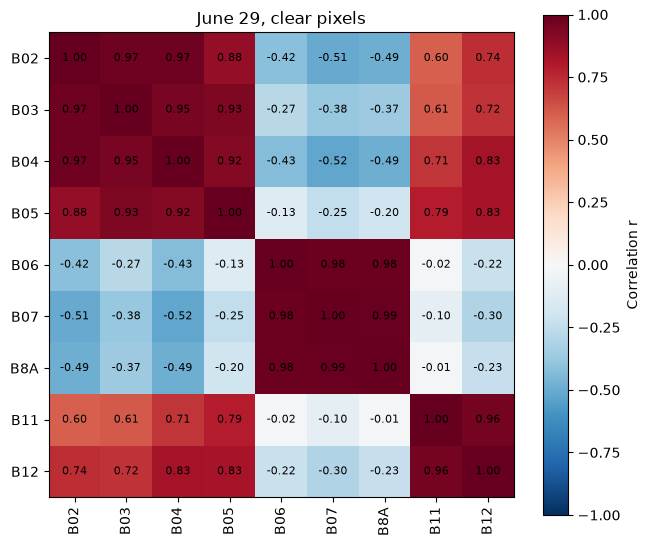

In [14]:
X = REFL[d][:, CLEAR_MASK[d]].T.astype("float64")          # (pixels, bands)
r = np.corrcoef(X, rowvar=False)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(r, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(BAND)), BAND, rotation=90); ax.set_yticks(range(len(BAND)), BAND)
for i in range(len(BAND)):
    for j in range(len(BAND)):
        ax.text(j, i, f"{r[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Correlation r")
ax.set_title("June 29, clear pixels")
plt.show()

### B2. OIF and SI for all 84 three-band combinations

- **OIF** = (s₁ + s₂ + s₃) ÷ (|r₁₂| + |r₁₃| + |r₂₃|): large standard deviations, small correlations.
- **SI** = determinant of the 3 × 3 covariance matrix: the volume the three bands span.

Reflectance is in percent here; the ranking does not depend on the units.

In [15]:
def rank_combinations(x):
    s = x.std(axis=0, ddof=1)
    r = np.corrcoef(x, rowvar=False)
    cov = np.cov(x, rowvar=False)
    rows = []
    for c in itertools.combinations(range(x.shape[1]), 3):
        oif = s[list(c)].sum() / sum(abs(r[i, j]) for i, j in itertools.combinations(c, 2))
        si = np.linalg.det(cov[np.ix_(c, c)])
        rows.append({"bands": "-".join(BAND[i] for i in c), "OIF": oif, "SI": si})
    t = pd.DataFrame(rows).set_index("bands")
    t["OIF rank"] = t["OIF"].rank(ascending=False).astype(int)
    t["SI rank"] = t["SI"].rank(ascending=False).astype(int)
    return t

ranks = rank_combinations(X * 100)
print("Top 5 by OIF"); display(ranks.sort_values("OIF", ascending=False).head(5).round({"OIF": 2, "SI": 0}))
print("Top 5 by SI");  display(ranks.sort_values("SI", ascending=False).head(5).round({"OIF": 2, "SI": 0}))
print("True color:");  display(ranks.loc[["B02-B03-B04"]].round({"OIF": 2, "SI": 0}))

Top 5 by OIF


,OIF,SI,OIF rank,SI rank
bands,,,,
B8A-B11-B12,21.04,12607.0,1,12
B06-B8A-B11,21.04,4417.0,2,29
B07-B8A-B11,20.65,2874.0,3,33
B06-B11-B12,19.50,7600.0,4,25
B05-B8A-B11,19.25,15975.0,5,5


Top 5 by SI


,OIF,SI,OIF rank,SI rank
bands,,,,
B04-B8A-B11,16.66,19312.0,13,1
B04-B07-B11,14.87,18430.0,22,2
B04-B8A-B12,13.49,17174.0,27,3
B05-B8A-B12,15.94,16424.0,16,4
B05-B8A-B11,19.25,15975.0,5,5


True color:


,OIF,SI,OIF rank,SI rank
bands,,,,
B02-B03-B04,3.33,3.0,83,84


### B3. Which band separates two land covers?

OIF and SI look at the whole image. To show a particular difference, look at the statistics of the classes you want to tell apart. For two classes, a simple measure for each band is the **separability M**:

M = |mean₁ − mean₂| ÷ (std₁ + std₂)

M compares the distance between the two class means with the spread of the classes. M > 1 means the two classes overlap little in that band; M < 1 means they overlap a lot. The classes come from the SCL: vegetation (4), not vegetated (5, mostly bare fields) and water (6).

In [16]:
class_stats = {}
for c in CLEAR:
    m = (SCL[d] == c) & ~np.isnan(REFL[d][0])
    class_stats[SCL_NAMES[c]] = (np.nanmean(REFL[d][:, m], axis=1), np.nanstd(REFL[d][:, m], axis=1, ddof=1))

means = pd.DataFrame({k: v[0] for k, v in class_stats.items()}, index=BAND).T
print("Class means (reflectance):"); display(means.round(3))

pairs = [("Water", "Vegetation"), ("Not vegetated", "Vegetation"), ("Water", "Not vegetated")]
M = pd.DataFrame({f"{a} vs {b}": np.abs(class_stats[a][0] - class_stats[b][0]) /
                  (class_stats[a][1] + class_stats[b][1]) for a, b in pairs}, index=BAND).T
print("Separability M (larger = better separated):"); display(M.round(2))
print("Best band for each pair:", M.idxmax(axis=1).to_dict())

Class means (reflectance):


,B02,B03,B04,B05,B06,B07,B8A,B11,B12
Vegetation,0.042,0.074,0.055,0.120,0.275,0.322,0.349,0.235,0.132
Not vegetated,0.094,0.121,0.142,0.177,0.209,0.229,0.254,0.362,0.303
Water,0.087,0.108,0.103,0.108,0.078,0.080,0.070,0.055,0.046


Separability M (larger = better separated):


,B02,B03,B04,B05,B06,B07,B8A,B11,B12
Water vs Vegetation,1.21,0.85,1.01,0.24,3.11,3.26,3.74,2.51,1.26
Not vegetated vs Vegetation,1.35,1.09,1.62,1.00,0.78,0.92,0.86,0.83,1.16
Water vs Not vegetated,0.13,0.24,0.66,1.07,1.75,1.87,2.08,2.27,2.02


Best band for each pair: {'Water vs Vegetation': 'B8A', 'Not vegetated vs Vegetation': 'B04', 'Water vs Not vegetated': 'B11'}


### B4. Your turn: your composite

Choose three bands for a composite that shows water, vegetation and bare fields as differently as possible. Use B1–B3 to decide: for example, the best band for each pair in B3, a top OIF or SI set, or a mix. Put the longest wavelength in red unless you have a reason not to. The cell shows your composite next to the top-ranked OIF set, both with a 2–98% stretch on clear pixels, and saves yours.

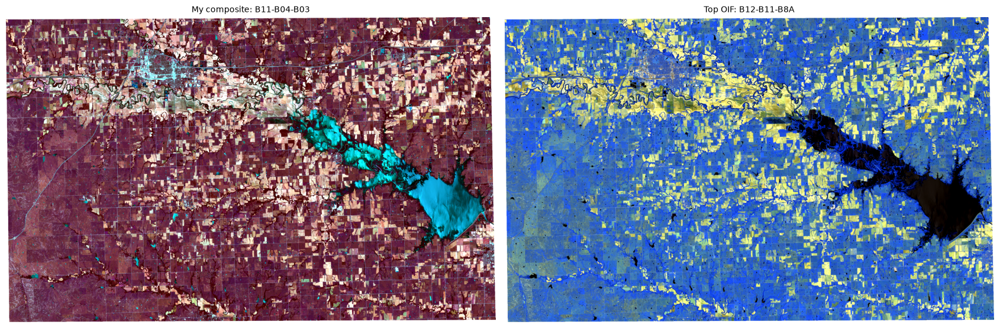

OIF rank and SI rank of my bands: {'OIF rank': 66, 'SI rank': 52}


In [23]:
# Your turn: choose three bands, in red, green, blue order
MY_BANDS = ["B11", "B04", "B03"]

top_oif = ranks.sort_values("OIF", ascending=False).index[0].split("-")[::-1]   # longest wavelength in red
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
show(axes[0], composite(REFL[d], MY_BANDS, "pct", CLEAR_MASK[d]), f"My composite: {'-'.join(MY_BANDS)}")
show(axes[1], composite(REFL[d], top_oif, "pct", CLEAR_MASK[d]), f"Top OIF: {'-'.join(top_oif)}")
plt.tight_layout()
plt.show()
plt.imsave(OUT_DIR / "partB_my_composite.png", composite(REFL[d], MY_BANDS, "pct", CLEAR_MASK[d]))
print("OIF rank and SI rank of my bands:",
      ranks.loc["-".join(sorted(MY_BANDS, key=BAND.index)), ["OIF rank", "SI rank"]].to_dict())

## Part C. Two dates, one picture

### C1. Clouds change the statistics

The red band of July 14, from all valid pixels and from clear pixels only, next to June 29.

In [24]:
rows = {}
for name, dd, mask in [("June 29, clear", "20190629", CLEAR_MASK["20190629"]),
                       ("July 14, all", "20190714", None),
                       ("July 14, clear", "20190714", CLEAR_MASK["20190714"])]:
    rows[name] = band_stats(REFL[dd], ["B04"], mask).loc["B04"]
pd.DataFrame(rows).T[["n", "p2", "median", "mean", "p98", "std"]].round(4)

,n,p2,median,mean,p98,std
"June 29, clear",5419594.0,0.0256,0.0569,0.0743,0.1800,0.0428
"July 14, all",5489774.0,0.0106,0.0950,0.2289,0.9806,0.2731
"July 14, clear",2124726.0,0.0202,0.0665,0.0820,0.2090,0.0492


### C2. One stretch for both dates, with clouds made transparent

To compare two dates, use the **same** stretch limits for both. Here the limits are the 2nd and 98th percentiles of the **June 29 clear pixels**, applied to both dates. On July 14, cloud and cloud-shadow pixels (SCL 3, 8, 9, 10) get alpha = 0, so they are drawn transparent over a gray background.

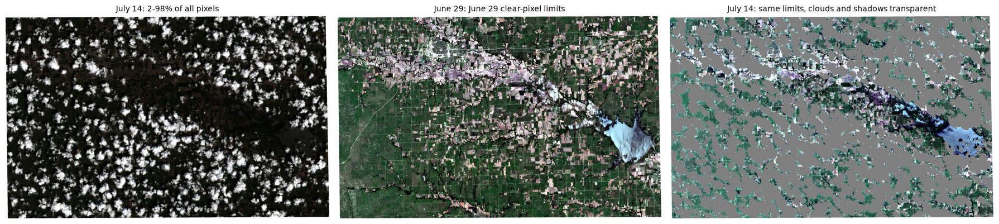

Limits used for both dates: {'B04': (0.0256, 0.18), 'B03': (0.0468, 0.1517), 'B02': (0.0231, 0.1212)}


In [25]:
fixed_limits = [limits(REFL["20190629"][B[b]], "pct", CLEAR_MASK["20190629"]) for b in TC]

def fixed_composite(refl, bands, lims):
    return np.nan_to_num(np.dstack([linear(refl[B[b]], *lim) for b, lim in zip(bands, lims)]), nan=1.0)

june = fixed_composite(REFL["20190629"], TC, fixed_limits)
july = fixed_composite(REFL["20190714"], TC, fixed_limits)
alpha = np.where(np.isin(SCL["20190714"], CLOUDY), 0.0, 1.0)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
show(axes[0], composite(REFL["20190714"], TC, "pct"), "July 14: 2-98% of all pixels")
show(axes[1], june, "June 29: June 29 clear-pixel limits")
axes[2].imshow(np.full(alpha.shape, 0.5), cmap="gray", vmin=0, vmax=1)
show(axes[2], np.dstack([july, alpha]), "July 14: same limits, clouds and shadows transparent")
plt.tight_layout()
plt.show()
print("Limits used for both dates:", {b: tuple(round(v, 4) for v in lim) for b, lim in zip(TC, fixed_limits)})

### C3. Your turn (optional): the same comparison for your composite

Replace `TC` with `MY_BANDS` in the cell above (in three places), run it again, and look for changes between the two dates in the clear areas.

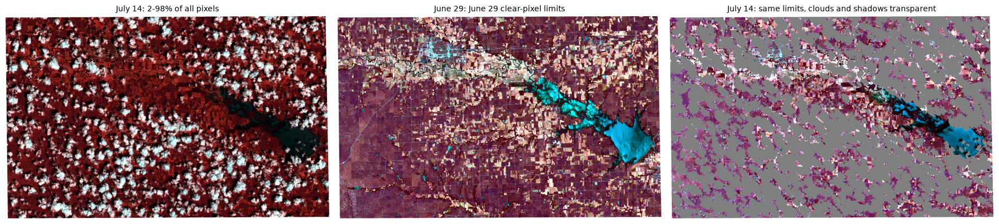

Limits used for both dates: {'B11': (0.0697, 0.4618), 'B04': (0.0256, 0.18), 'B03': (0.0468, 0.1517)}


In [26]:
fixed_limits = [limits(REFL["20190629"][B[b]], "pct", CLEAR_MASK["20190629"]) for b in MY_BANDS]

def fixed_composite(refl, bands, lims):
    return np.nan_to_num(np.dstack([linear(refl[B[b]], *lim) for b, lim in zip(bands, lims)]), nan=1.0)

june = fixed_composite(REFL["20190629"], MY_BANDS, fixed_limits)
july = fixed_composite(REFL["20190714"], MY_BANDS, fixed_limits)
alpha = np.where(np.isin(SCL["20190714"], CLOUDY), 0.0, 1.0)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
show(axes[0], composite(REFL["20190714"], MY_BANDS, "pct"), "July 14: 2-98% of all pixels")
show(axes[1], june, "June 29: June 29 clear-pixel limits")
axes[2].imshow(np.full(alpha.shape, 0.5), cmap="gray", vmin=0, vmax=1)
show(axes[2], np.dstack([july, alpha]), "July 14: same limits, clouds and shadows transparent")
plt.tight_layout()
plt.show()
print("Limits used for both dates:", {b: tuple(round(v, 4) for v in lim) for b, lim in zip(MY_BANDS, fixed_limits)})

## Questions

Answer each question in the cell below it, in two to four sentences. Use numbers from your outputs.

**1.** In A2, the min–max image looks almost the same as an unstretched image. Which numbers in the A1 table explain why?

*The min–max limits come from the min (0.013–0.022) and the max (1.07–1.09). Together they span almost the full 0–1 range, which is what an unstretched image already shows. But 98% of pixels are below p98 (0.12–0.18), and the means are only 0.05–0.08. As a result, for red, p98 maps to only about 0.15 (about 40/255), so nearly the whole image stays dark.*

**2.** In A2, the standard-deviation stretch of the red band starts below 0. What does that mean for the display, and how does the red band's skewness make mean ± 2 std a poor fit?

*The lower limit is 0.0743 − 2(0.0428) = −0.011. Reflectance can’t be negative, so the bottom of the display range is wasted and even the darkest pixel (0.013) shows as gray (about 36/255) instead of black. The red band is right-skewed (skewness 1.52), with a long bright tail that pulls the mean (0.074) above the median (0.057) and inflates the std. Mean ± 2 std assumes a symmetric histogram, so it sets the low limit below the data and the high limit (0.160) below p98 (0.180), which clips the bright fields.*

**3.** Which settings did you choose in A3 for your final true-color image? Justify the choice with the statistics or the histogram, not only with how it looks. If you used gamma or the log curve, explain why with the skewness or with the gap between the 98th percentile and the maximum.

*I used a percent clip of 1–99% with gamma 1.2, which gave limits of 0.0239–0.1949 for B04, 0.0447–0.1646 for B03 and 0.0218–0.1333 for B02. The bands are strongly right-skewed (skewness 1.52–2.41), and the gap between p98 (0.12–0.18) and max (about 1.08) shows that a few outliers would control a min–max stretch, so a percent clip is the right choice. Because of the skew, most pixels sit at the dark end: the red median (0.057) falls at only about 19% of the display range. Gamma 1.2 brightens these mid-tones to about 25%.*

**4.** From B1 and B2: which groups of bands are redundant (r ≥ 0.95)? Why does true color rank near the bottom by OIF and SI?

*Three groups of bands are redundant: the visible bands B02–B03–B04 (r = 0.95–0.97), the red-edge/NIR bands B06–B07–B8A (r = 0.98–0.99), and the SWIR bands B11–B12 (r = 0.96). True color takes all three bands from the visible group, so the correlations are high (sum of |r| = 2.89). Their standard deviations are also small (0.027–0.043). This gives an OIF of only 3.33 (rank 83 of 84) and an SI of 3 (rank 84).*

**5.** From B3: which band best separates water from vegetation, bare fields from vegetation, and water from bare fields? Which bands did you choose in B4, and how did these numbers guide you? Compare your choice with the top OIF and SI sets.

*B8A best separates water from vegetation (M = 3.74), B04 best separates bare fields from vegetation (M = 1.62), and B11 best separates water from bare fields (M = 2.27). I chose B11-B04-B03: B11 separates water from both other classes (M = 2.51 and 2.27), and B04 is the best band for bare fields vs. vegetation. My set ranks only 66 by OIF and 52 by SI, because B03 and B04 are highly correlated (r = 0.95). The top OIF set is B8A-B11-B12 (OIF 21.04) and the top SI set is B04-B8A-B11 (SI 19,312). The top SI set is exactly the three best bands from B3.*

**6.** From C1 and C2: how much do clouds change the mean and the 98th percentile of the July 14 red band? Why do the June 29 limits make the two dates comparable, and what difference between the dates can you see in the clear areas?

*Clouds raise the July 14 red mean from 0.0820 (clear pixels) to 0.2289 (all pixels), and the 98th percentile from 0.2090 to 0.9806. With the June 29 limits on both dates, the same reflectance gets the same brightness, so any color difference is a real change on the ground rather than an effect of the stretch. In the clear areas on July 14, the turbid light-blue water and the flooded floodplain in the lake’s upper arm look darker and smaller. The fields are also slightly brighter in red (mean 0.082 vs. 0.074, p98 0.209 vs. 0.180).*